In [1]:
import warnings

warnings.filterwarnings("ignore")
# the location of R (used for the mclust clustering)
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'
import rpy2.robjects as robjects
import rpy2.robjects.numpy2ri

import anndata
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scipy.linalg
from sklearn.metrics import adjusted_rand_score as ari_score
import time
import torch
import STAligner

used_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


In [2]:
# for loading DLPFC12 data·
def load_DLPFC(root_dir=r'C:\Code\Data\DLPFC/', section_id='151507'):
    # 151507, ..., 151676 12 in total
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file='filtered_feature_bc_matrix.h5',
                        load_images=True)
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    # print(ad.obs)
    return ad

In [22]:
# 定义要处理的切片ID列表
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_ids = ['151673', '151674', '151675', '151676']
Batch_list = []
adj_list = []
dataset = section_ids[0] + '_' + section_ids[1] + '_' + section_ids[2] + '_' + section_ids[3]
print(dataset)
start_time = time.time()
for section_id in section_ids:
    adata = load_DLPFC(root_dir='C:\Code\Data\DLPFC/', section_id=section_id)
    adata.var_names_make_unique(join="++")

    # make spot name unique
    adata.obs_names = [x + '_' + section_id for x in adata.obs_names]

    adata.X = sp.csr_matrix(adata.X)

    # Constructing the spatial network
    STAligner.Cal_Spatial_Net(adata, rad_cutoff=150)  # the spatial network are saved in adata.uns[‘adj’]
    # STAligner.Stats_Spatial_Net(adata) # plot the number of spatial neighbors

    # Normalization
    sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=5000)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata = adata[:, adata.var['highly_variable']]

    adj_list.append(adata.uns['adj'])
    Batch_list.append(adata)

adata_concat = anndata.concat(Batch_list, label="slice_name", keys=section_ids)
adata_concat.obs['original_clusters'] = adata_concat.obs['original_clusters'].astype('category')
adata_concat.obs["batch_name"] = adata_concat.obs["slice_name"].astype('category')
print('adata_concat.shape: ', adata_concat.shape)

adj_concat = np.asarray(adj_list[0].todense())
for batch_id in range(1, len(section_ids)):
    adj_concat = scipy.linalg.block_diag(adj_concat, np.asarray(adj_list[batch_id].todense()))
adata_concat.uns['edgeList'] = np.nonzero(adj_concat)

adata_concat = STAligner.train_STAligner(adata_concat, verbose=True, knn_neigh=50, device=used_device)

# 根据dataset确定聚类数量
if "151669" in dataset and "151670" in dataset and "151671" in dataset and "151672" in dataset:
    num_cluster = 5  # 第二组切片
elif "151507" in dataset and "151508" in dataset and "151509" in dataset and "151510" in dataset:
    num_cluster = 7  # 第一组切片
elif "151673" in dataset and "151674" in dataset and "151675" in dataset and "151676" in dataset:
    num_cluster = 7  # 第三组切片

STAligner.mclust_R(adata_concat, num_cluster=num_cluster, used_obsm='STAligner')
adata_concat = adata_concat[adata_concat.obs['original_clusters'] != 'unknown']

print('mclust, ARI = %01.3f' % ari_score(adata_concat.obs['original_clusters'], adata_concat.obs['mclust']))

# embedding in adata.obsm:key='STAligner'
# print(adata_concat.obs)
# print(adata_concat.obsm['STAligner'])
df_labels = adata_concat.obs[['original_clusters', 'mclust']]
embed_ = adata_concat.obsm['STAligner']
# adata_concat.write_h5ad(os.path.join(save_dir_gt, dataset, 'iter'+str(iter_)+'.h5ad'))


151673_151674_151675_151676
------Calculating spatial graph...
The graph contains 21038 edges, 3611 cells.
5.8261 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 21134 edges, 3635 cells.
5.8140 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 20688 edges, 3566 cells.
5.8015 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 19966 edges, 3431 cells.
5.8193 neighbors per cell on average.
adata_concat.shape:  (14243, 1134)
STAligner(
  (conv1): GATConv(1134, 512, heads=1)
  (conv2): GATConv(512, 30, heads=1)
  (conv3): GATConv(30, 512, heads=1)
  (conv4): GATConv(512, 1134, heads=1)
)
Pretrain with STAGATE...


100%|██████████| 500/500 [00:07<00:00, 62.83it/s]


Train with STAligner...


  0%|          | 0/500 [00:00<?, ?it/s]

Update spot triplets at epoch 500


...

Update spot triplets at epoch 800


 79%|███████▉  | 396/500 [00:24<00:01, 54.69it/s]

Update spot triplets at epoch 900


100%|██████████| 500/500 [00:30<00:00, 16.36it/s]


fitting ...
  |======================================================================| 100%
mclust, ARI = 0.574


In [23]:
# 过滤掉没有layer_guess标签的细胞
sub_adata = adata_concat[~pd.isnull(adata_concat.obs['original_clusters'])]
ARI = ari_score(sub_adata.obs['original_clusters'], sub_adata.obs['mclust'])
print(f"总体ARI分数: {ARI}")

# 按切片计算ARI
proj_list = section_ids
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_adata_tmp.obs['original_clusters'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI: {ARI}")


总体ARI分数: 0.5743508375466787
151673 ARI: 0.541653555956227
151674 ARI: 0.6196642214826326
151675 ARI: 0.571011798121145
151676 ARI: 0.5842883458642316


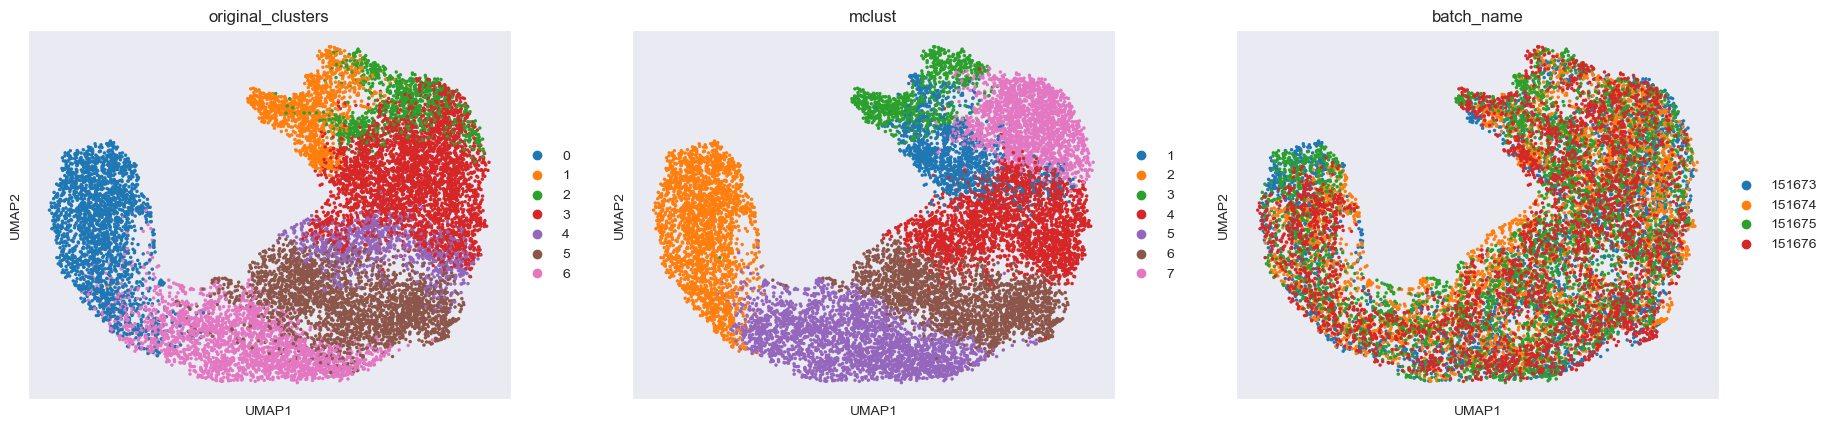

In [24]:
import scanpy as sc

sc.pp.neighbors(adata_concat, use_rep='STAligner', metric='cosine')
sc.tl.umap(adata_concat)
sc.pl.umap(adata_concat, color=['original_clusters', 'mclust', 'batch_name'],
           show=True, size=25, save=False)

In [25]:
from STG3Net.Metrics import compute_ARI, compute_NMI, compute_HOM, compute_COM, compute_PAS, compute_CHAOS
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import harmonypy as hm

# 定义新的计算指标函数
def compute_metrics(adata, true_label_key, pred_label_key):
    # 使用Metrics.py中定义的函数计算各项指标
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_ids:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

整个数据集的指标:
ARI: 0.5743508375466787
NMI: 0.6798233008898503
HOM: 0.6870706614361283
COM: 0.6727272376834796
CHAOS: 0.01985894017975059
PAS: 0.25170259074633156

每个切片的指标:

切片 151673:
ARI: 0.541653555956227
NMI: 0.6748225174874571
HOM: 0.6865346768075056
COM: 0.6635032698680875
CHAOS: 0.061058492397268335
PAS: 0.048739961229576294

切片 151674:
ARI: 0.6196642214826326
NMI: 0.7218262004153115
HOM: 0.7276460344234701
COM: 0.7160987237187615
CHAOS: 0.060304767541056695
PAS: 0.04869325997248968

切片 151675:
ARI: 0.571011798121145
NMI: 0.6807903993793772
HOM: 0.6860260822853964
COM: 0.6756340276022899
CHAOS: 0.062397904733739934
PAS: 0.04879416713404375

切片 151676:
ARI: 0.5842883458642316
NMI: 0.691107704576854
HOM: 0.6981337872178771
COM: 0.6842216351140861
CHAOS: 0.06305314848910451
PAS: 0.050131157097056255


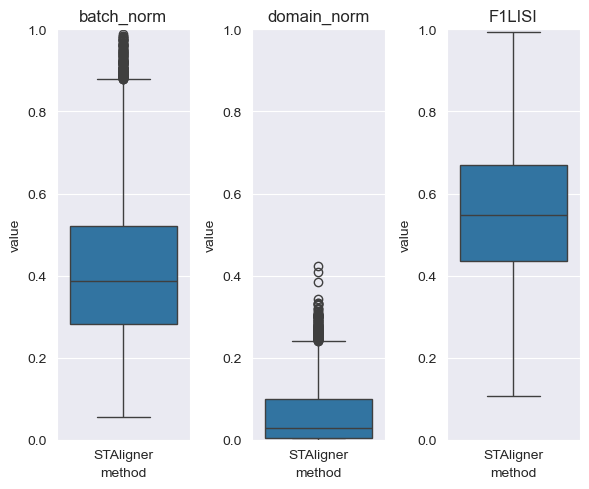

In [26]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'STAligner', 'batch_name', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'STAligner',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

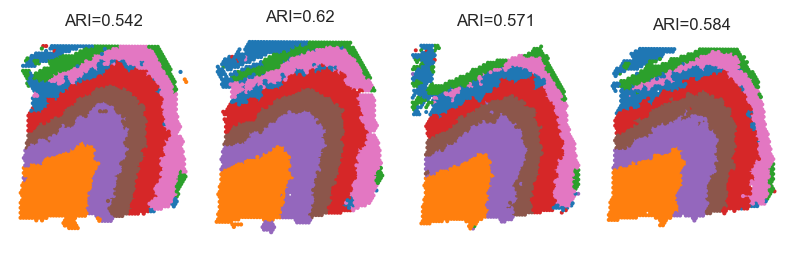

In [27]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(sub_adata[sub_adata.obs['batch_name'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(proj_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [28]:
file_name = 'STAligner_Donor3.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'
# 修改保存前的代码
edge_indices = np.nonzero(adj_concat)
sub_adata.uns['edgeList'] = np.vstack(edge_indices).T  # 转换为 N×2 的数组
sub_adata.write(file_path)

151669_151670_151671_151672
------Calculating spatial graph...
The graph contains 21132 edges, 3636 cells.
5.8119 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 20340 edges, 3484 cells.
5.8381 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 23970 edges, 4093 cells.
5.8563 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 22770 edges, 3888 cells.
5.8565 neighbors per cell on average.
adata_concat.shape:  (15101, 938)
STAligner(
  (conv1): GATConv(938, 512, heads=1)
  (conv2): GATConv(512, 30, heads=1)
  (conv3): GATConv(30, 512, heads=1)
  (conv4): GATConv(512, 938, heads=1)
)
Pretrain with STAGATE...


100%|██████████| 500/500 [00:08<00:00, 62.39it/s]


Train with STAligner...


  0%|          | 0/500 [00:00<?, ?it/s]

Update spot triplets at epoch 500


...

Update spot triplets at epoch 800


 80%|███████▉  | 399/500 [00:23<00:01, 55.20it/s]

Update spot triplets at epoch 900


100%|██████████| 500/500 [00:28<00:00, 17.31it/s]


fitting ...
  |======================================================================| 100%
mclust, ARI = 0.465
总体ARI分数: 0.4654469087243005
151669 ARI: 0.41420518739100437
151670 ARI: 0.4018445474236939
151671 ARI: 0.5601259667410953
151672 ARI: 0.5808253775114575


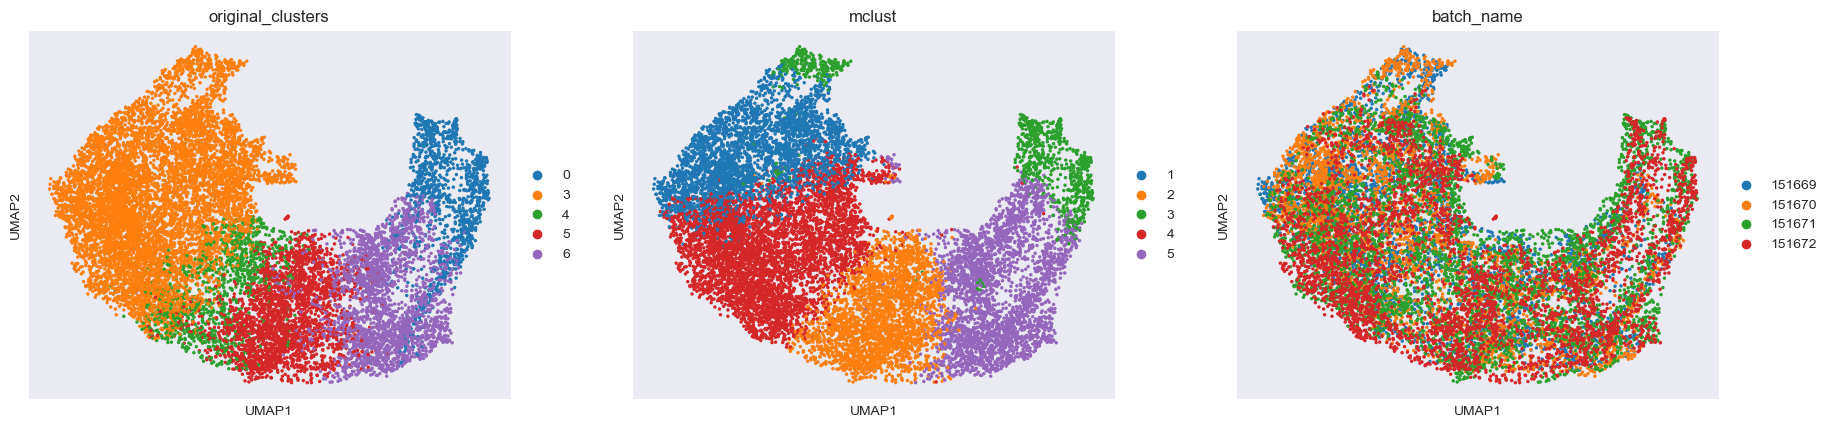

整个数据集的指标:
ARI: 0.4654469087243005
NMI: 0.5928743157705907
HOM: 0.6321729280989223
COM: 0.5581756926836491
CHAOS: 0.024913737164052256
PAS: 0.32878617310111913

每个切片的指标:

切片 151669:
ARI: 0.41420518739100437
NMI: 0.5788965834505635
HOM: 0.6315771938099902
COM: 0.5343276721932333
CHAOS: 0.06148427424337013
PAS: 0.052255225522552254

切片 151670:
ARI: 0.4018445474236939
NMI: 0.5524844748735129
HOM: 0.6254501588873632
COM: 0.49476469656962835
CHAOS: 0.061303054411596974
PAS: 0.04936854190585534

切片 151671:
ARI: 0.5601259667410953
NMI: 0.6615393671626699
HOM: 0.6952656897427834
COM: 0.6309336956062992
CHAOS: 0.0580351125243772
PAS: 0.04373320302956267

切片 151672:
ARI: 0.5808253775114575
NMI: 0.6674598226861623
HOM: 0.6779253719429945
COM: 0.6573124871589834
CHAOS: 0.06117710521704262
PAS: 0.041923868312757205


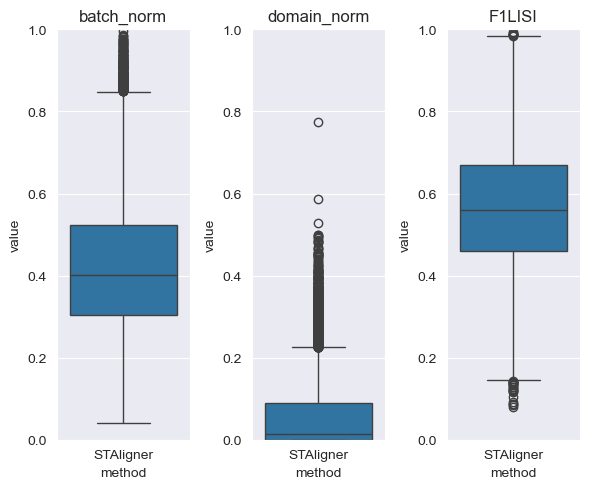

In [16]:
# 定义要处理的切片ID列表
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_ids = ['151669','151670','151671','151672']
Batch_list = []
adj_list = []
dataset = section_ids[0] + '_' + section_ids[1] + '_' + section_ids[2] + '_' + section_ids[3]
print(dataset)
start_time = time.time()
for section_id in section_ids:
    adata = load_DLPFC(root_dir='C:\Code\Data\DLPFC/', section_id=section_id)
    adata.var_names_make_unique(join="++")

    # make spot name unique
    adata.obs_names = [x + '_' + section_id for x in adata.obs_names]

    adata.X = sp.csr_matrix(adata.X)

    # Constructing the spatial network
    STAligner.Cal_Spatial_Net(adata, rad_cutoff=150)  # the spatial network are saved in adata.uns[‘adj’]
    # STAligner.Stats_Spatial_Net(adata) # plot the number of spatial neighbors

    # Normalization
    sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=5000)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata = adata[:, adata.var['highly_variable']]

    adj_list.append(adata.uns['adj'])
    Batch_list.append(adata)

adata_concat = anndata.concat(Batch_list, label="slice_name", keys=section_ids)
adata_concat.obs['original_clusters'] = adata_concat.obs['original_clusters'].astype('category')
adata_concat.obs["batch_name"] = adata_concat.obs["slice_name"].astype('category')
print('adata_concat.shape: ', adata_concat.shape)

adj_concat = np.asarray(adj_list[0].todense())
for batch_id in range(1, len(section_ids)):
    adj_concat = scipy.linalg.block_diag(adj_concat, np.asarray(adj_list[batch_id].todense()))
adata_concat.uns['edgeList'] = np.nonzero(adj_concat)

adata_concat = STAligner.train_STAligner(adata_concat, verbose=True, knn_neigh=50, device=used_device)

# 根据dataset确定聚类数量
if "151669" in dataset and "151670" in dataset and "151671" in dataset and "151672" in dataset:
    num_cluster = 5  # 第二组切片
elif "151507" in dataset and "151508" in dataset and "151509" in dataset and "151510" in dataset:
    num_cluster = 7  # 第一组切片
elif "151673" in dataset and "151674" in dataset and "151675" in dataset and "151676" in dataset:
    num_cluster = 7  # 第三组切片

STAligner.mclust_R(adata_concat, num_cluster=num_cluster, used_obsm='STAligner')
adata_concat = adata_concat[adata_concat.obs['original_clusters'] != 'unknown']

print('mclust, ARI = %01.3f' % ari_score(adata_concat.obs['original_clusters'], adata_concat.obs['mclust']))

# embedding in adata.obsm:key='STAligner'
# print(adata_concat.obs)
# print(adata_concat.obsm['STAligner'])
df_labels = adata_concat.obs[['original_clusters', 'mclust']]
embed_ = adata_concat.obsm['STAligner']
# adata_concat.write_h5ad(os.path.join(save_dir_gt, dataset, 'iter'+str(iter_)+'.h5ad'))
# 过滤掉没有layer_guess标签的细胞
sub_adata = adata_concat[~pd.isnull(adata_concat.obs['original_clusters'])]
ARI = ari_score(sub_adata.obs['original_clusters'], sub_adata.obs['mclust'])
print(f"总体ARI分数: {ARI}")

# 按切片计算ARI
proj_list = section_ids
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_adata_tmp.obs['original_clusters'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI: {ARI}")
import scanpy as sc

sc.pp.neighbors(adata_concat, use_rep='STAligner', metric='cosine')
sc.tl.umap(adata_concat)
sc.pl.umap(adata_concat, color=['original_clusters', 'mclust', 'batch_name'],
           show=True, size=25, save=False)

# 定义新的计算指标函数
def compute_metrics(adata, true_label_key, pred_label_key):
    # 使用Metrics.py中定义的函数计算各项指标
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_ids:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'STAligner', 'batch_name', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'STAligner',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

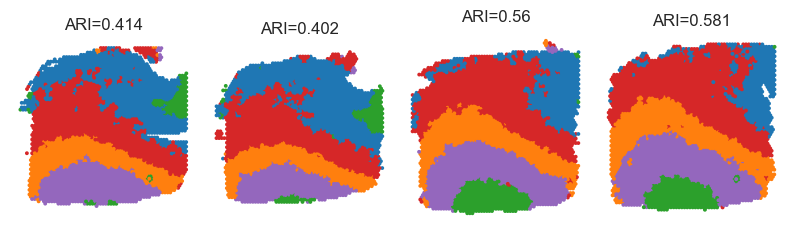

In [17]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(sub_adata[sub_adata.obs['batch_name'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(proj_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [18]:
file_name = 'STAligner_Donor2.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'
# 修改保存前的代码
edge_indices = np.nonzero(adj_concat)
sub_adata.uns['edgeList'] = np.vstack(edge_indices).T  # 转换为 N×2 的数组
sub_adata.write(file_path)

151507_151508_151509_151510
------Calculating spatial graph...
The graph contains 24762 edges, 4221 cells.
5.8664 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 25692 edges, 4381 cells.
5.8644 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 28166 edges, 4788 cells.
5.8826 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 26994 edges, 4595 cells.
5.8746 neighbors per cell on average.
adata_concat.shape:  (17985, 1074)
STAligner(
  (conv1): GATConv(1074, 512, heads=1)
  (conv2): GATConv(512, 30, heads=1)
  (conv3): GATConv(30, 512, heads=1)
  (conv4): GATConv(512, 1074, heads=1)
)
Pretrain with STAGATE...


100%|██████████| 500/500 [00:09<00:00, 50.34it/s]


Train with STAligner...


  0%|          | 0/500 [00:00<?, ?it/s]

Update spot triplets at epoch 500


...

Update spot triplets at epoch 800


 80%|████████  | 400/500 [00:27<00:02, 45.22it/s]

Update spot triplets at epoch 900


100%|██████████| 500/500 [00:33<00:00, 14.82it/s]


fitting ...
  |======================================================================| 100%
mclust, ARI = 0.477
总体ARI分数: 0.47716416172129045
151507 ARI: 0.4790744286480739
151508 ARI: 0.4846622473496449
151509 ARI: 0.4914144833556536
151510 ARI: 0.46586973898181355


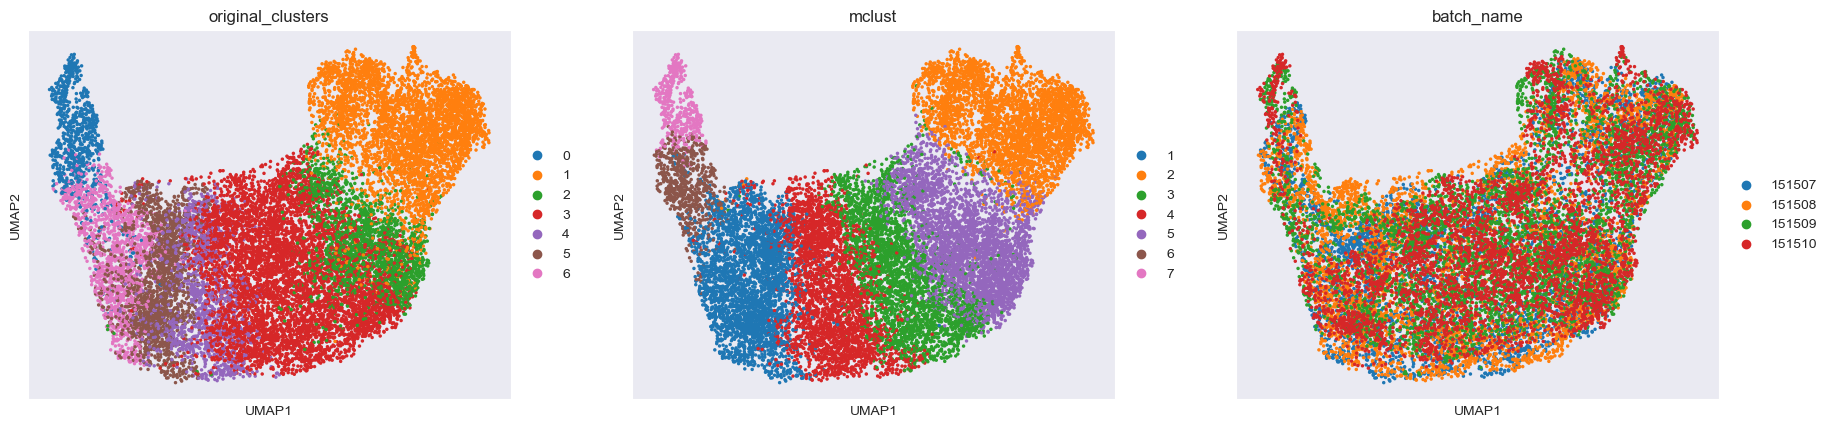

整个数据集的指标:
ARI: 0.47716416172129045
NMI: 0.6245703833544366
HOM: 0.6332139560237109
COM: 0.616159607980977
CHAOS: 0.02806931251842707
PAS: 0.7859327217125383

每个切片的指标:

切片 151507:
ARI: 0.4790744286480739
NMI: 0.6452573118283367
HOM: 0.6340511419943174
COM: 0.656866722430001
CHAOS: 0.05703943284166496
PAS: 0.05709547500592277

切片 151508:
ARI: 0.4846622473496449
NMI: 0.639215442617232
HOM: 0.6412581222287886
COM: 0.6371857352885749
CHAOS: 0.05596259306685689
PAS: 0.06322757361333028

切片 151509:
ARI: 0.4914144833556536
NMI: 0.6607195473232028
HOM: 0.6888093654528532
COM: 0.6348309811983707
CHAOS: 0.054125778253404415
PAS: 0.06203007518796992

切片 151510:
ARI: 0.46586973898181355
NMI: 0.6211257461850509
HOM: 0.643687737803646
COM: 0.6000918406378422
CHAOS: 0.055676030653432865
PAS: 0.06289445048966268


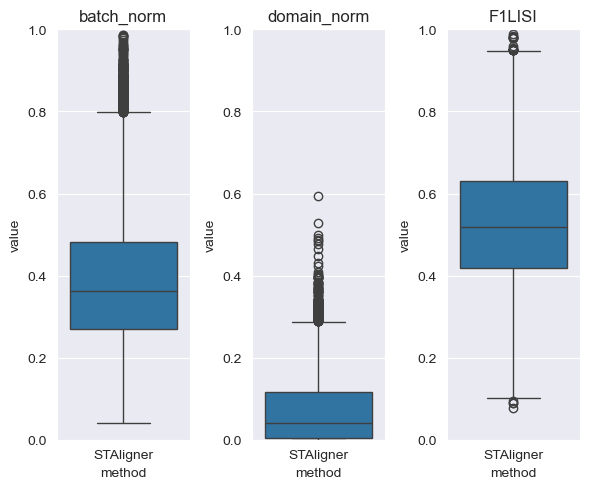

In [20]:
# 定义要处理的切片ID列表
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_ids = ['151507','151508','151509','151510']
Batch_list = []
adj_list = []
dataset = section_ids[0] + '_' + section_ids[1] + '_' + section_ids[2] + '_' + section_ids[3]
print(dataset)
start_time = time.time()
for section_id in section_ids:
    adata = load_DLPFC(root_dir='C:\Code\Data\DLPFC/', section_id=section_id)
    adata.var_names_make_unique(join="++")

    # make spot name unique
    adata.obs_names = [x + '_' + section_id for x in adata.obs_names]

    adata.X = sp.csr_matrix(adata.X)

    # Constructing the spatial network
    STAligner.Cal_Spatial_Net(adata, rad_cutoff=150)  # the spatial network are saved in adata.uns[‘adj’]
    # STAligner.Stats_Spatial_Net(adata) # plot the number of spatial neighbors

    # Normalization
    sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=5000)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata = adata[:, adata.var['highly_variable']]

    adj_list.append(adata.uns['adj'])
    Batch_list.append(adata)

adata_concat = anndata.concat(Batch_list, label="slice_name", keys=section_ids)
adata_concat.obs['original_clusters'] = adata_concat.obs['original_clusters'].astype('category')
adata_concat.obs["batch_name"] = adata_concat.obs["slice_name"].astype('category')
print('adata_concat.shape: ', adata_concat.shape)

adj_concat = np.asarray(adj_list[0].todense())
for batch_id in range(1, len(section_ids)):
    adj_concat = scipy.linalg.block_diag(adj_concat, np.asarray(adj_list[batch_id].todense()))
adata_concat.uns['edgeList'] = np.nonzero(adj_concat)

adata_concat = STAligner.train_STAligner(adata_concat, verbose=True, knn_neigh=50, device=used_device)

# 根据dataset确定聚类数量
if "151669" in dataset and "151670" in dataset and "151671" in dataset and "151672" in dataset:
    num_cluster = 5  # 第二组切片
elif "151507" in dataset and "151508" in dataset and "151509" in dataset and "151510" in dataset:
    num_cluster = 7  # 第一组切片
elif "151673" in dataset and "151674" in dataset and "151675" in dataset and "151676" in dataset:
    num_cluster = 7  # 第三组切片

STAligner.mclust_R(adata_concat, num_cluster=num_cluster, used_obsm='STAligner')
adata_concat = adata_concat[adata_concat.obs['original_clusters'] != 'unknown']

print('mclust, ARI = %01.3f' % ari_score(adata_concat.obs['original_clusters'], adata_concat.obs['mclust']))

# embedding in adata.obsm:key='STAligner'
# print(adata_concat.obs)
# print(adata_concat.obsm['STAligner'])
df_labels = adata_concat.obs[['original_clusters', 'mclust']]
embed_ = adata_concat.obsm['STAligner']
# adata_concat.write_h5ad(os.path.join(save_dir_gt, dataset, 'iter'+str(iter_)+'.h5ad'))
# 过滤掉没有layer_guess标签的细胞
sub_adata = adata_concat[~pd.isnull(adata_concat.obs['original_clusters'])]
ARI = ari_score(sub_adata.obs['original_clusters'], sub_adata.obs['mclust'])
print(f"总体ARI分数: {ARI}")

# 按切片计算ARI
proj_list = section_ids
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_adata_tmp.obs['original_clusters'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI: {ARI}")

import scanpy as sc

sc.pp.neighbors(adata_concat, use_rep='STAligner', metric='cosine')
sc.tl.umap(adata_concat)
sc.pl.umap(adata_concat, color=['original_clusters', 'mclust', 'batch_name'],
           show=True, size=25, save=False)

# 定义新的计算指标函数
def compute_metrics(adata, true_label_key, pred_label_key):
    # 使用Metrics.py中定义的函数计算各项指标
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_ids:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'STAligner', 'batch_name', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'STAligner',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

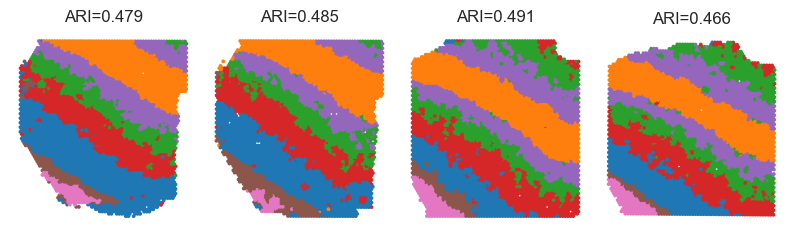

In [21]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(sub_adata[sub_adata.obs['batch_name'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(proj_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

file_name = 'STAligner_Donor1.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'
# 修改保存前的代码
edge_indices = np.nonzero(adj_concat)
sub_adata.uns['edgeList'] = np.vstack(edge_indices).T  # 转换为 N×2 的数组
sub_adata.write(file_path)